# HAI22.04 — Figura real vs. estimado (cierre de Etapa 1)

**Objetivo:** una figura de cuatro paneles (P1–P4) con observaciones reales, XGBoost FULL y Persistencia FULL en **TEST4**. Usa exclusivamente predicciones ya almacenadas: **no entrena**, **no ajusta umbrales** y **no usa etiquetas de ataque**.

**Selección reproducible:** en cada componente se elige la señal cuyo $R^2$ de XGBoost en TEST4 esté más próximo a la mediana de las señales de ese mismo componente. Los empates se resuelven por nombre. Se representa una ventana fija de **800 registros**, iniciada al 10 % de TEST4 (sin buscar ventanas de mayor error ni seleccionar según el aspecto de las curvas). El gráfico es ilustrativo, no demuestra identificación de regímenes.

**Salida:** `resultados_hai_arboles/analisis/etapa_1/figura_real_vs_estimado/`. No sobrescribe experimentos originales.

In [1]:
from pathlib import Path
import os
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get('HAI_ROOT', r'C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles'))
TEST = 'test4'
WINDOW = 800
START_FRACTION = 0.10
OUT = ROOT / 'analisis' / 'etapa_1' / 'figura_real_vs_estimado'
assert ROOT.is_dir(), f'No existe la carpeta del proyecto: {ROOT}'
OUT.mkdir(parents=True, exist_ok=True)
print('Origen:', ROOT)
print('Salida:', OUT)

Origen: C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles
Salida: C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles\analisis\etapa_1\figura_real_vs_estimado


## 1. Selección de señales usando las métricas ya calculadas

No volvemos a calcular $R^2$. El archivo `12_r2_desde_predicciones.csv` es el resultado de la Etapa 1 y permite justificar las cuatro señales.

In [2]:
metrics_path = ROOT / 'analisis' / 'etapa_1' / '12_r2_desde_predicciones.csv'
assert metrics_path.is_file(), f'Falta {metrics_path}. Ejecuta primero el notebook 07.'
metrics = pd.read_csv(metrics_path, encoding='utf-8-sig')
required = {'modelo', 'test', 'componente', 'variable', 'r2'}
assert required <= set(metrics.columns), f'Columnas ausentes: {required-set(metrics.columns)}'
xgb = metrics[(metrics.modelo.astype(str).str.upper().isin(['XGB','XGBOOST'])) &
              (metrics.test.astype(str).str.lower() == TEST)].copy()
xgb['r2'] = pd.to_numeric(xgb.r2, errors='coerce')
xgb = xgb[np.isfinite(xgb.r2)].copy()
selected = []
for comp in ('P1', 'P2', 'P3', 'P4'):
    part = xgb[xgb.componente == comp].copy()
    assert not part.empty, f'No hay métricas XGB/{TEST}/{comp}'
    assert not part.variable.duplicated().any(), f'Señales duplicadas para {comp}'
    median = float(part.r2.median())
    part['distancia_mediana'] = (part.r2 - median).abs()
    part = part.sort_values(['distancia_mediana','variable'])
    winner = part.iloc[0]
    selected.append(dict(componente=comp, variable=str(winner.variable), r2_xgb=float(winner.r2),
                         mediana_r2_componente=median, criterio='R2_XGB_mas_cercano_mediana_TEST4'))
selection = pd.DataFrame(selected)
selection.to_csv(OUT/'seleccion_senales.csv', index=False, encoding='utf-8-sig')
display(selection)

,componente,variable,r2_xgb,mediana_r2_componente,criterio
0,P1,P1_LIT01,0.986731,0.986731,R2_XGB_mas_cercano_mediana_TEST4
1,P2,P2_VIBTR04,0.050774,0.025375,R2_XGB_mas_cercano_mediana_TEST4
2,P3,P3_PIT01,0.998084,0.998084,R2_XGB_mas_cercano_mediana_TEST4
3,P4,P4_ST_PT01,0.979429,0.879299,R2_XGB_mas_cercano_mediana_TEST4


## 2. Lectura selectiva de archivos GZIP

Se leen únicamente las columnas de las cuatro señales seleccionadas, más `indice` y `timestamp`. Los archivos permanecen comprimidos. Se comprueba que los registros de XGBoost y persistencia coincidan exactamente en el orden y los valores reales.

In [3]:
def prediction_file(model):
    folder = ROOT/'predicciones'
    assert folder.is_dir(), f'No existe {folder}'
    candidates = [p for p in folder.rglob('*') if p.is_file() and
                  p.name.lower() in (f'{model.lower()}_full_{TEST}.csv.gz',
                                      f'{model.lower()}_full_{TEST}.csv')]
    assert len(candidates)==1, f'Se esperaba exactamente un archivo {model}_FULL_{TEST}; encontrados: {candidates}'
    return candidates[0]

def compression_of(path):
    with path.open('rb') as f:
        return 'gzip' if f.read(2)==b'\x1f\x8b' else None

def read_window(path, requested_columns, start, size):
    # Primero lee el encabezado y comprueba columnas reales; después lee solo la ventana.
    comp = compression_of(path)
    cols = pd.read_csv(path, compression=comp, nrows=0).columns.tolist()
    absent = set(requested_columns)-set(cols)
    assert not absent, f'{path.name}: columnas ausentes {absent}'
    # Avanzar secuencialmente en bloques, sin cargar el TEST entero en memoria.
    chunks = pd.read_csv(path, compression=comp, usecols=requested_columns,
                         chunksize=5000, low_memory=False)
    parts=[]; offset=0; stop=start+size
    for chunk in chunks:
        right=offset+len(chunk)
        if right>start and offset<stop:
            lo=max(0,start-offset); hi=min(len(chunk),stop-offset)
            parts.append(chunk.iloc[lo:hi].copy())
        offset=right
        if offset>=stop:break
    assert parts, f'{path.name}: no contiene filas en el intervalo solicitado'
    result=pd.concat(parts, ignore_index=True)
    assert len(result)==size, f'{path.name}: ventana incompleta ({len(result)}/{size})'
    return result

xgb_file=prediction_file('XGB')
persist_file=prediction_file('PERSIST')
print('XGBoost:', xgb_file.name, '| Persistencia:', persist_file.name)
# N de TEST4 documentado en resultados de Etapa 1 (todas las señales deben coincidir).
n_by_signal = metrics[(metrics.test.astype(str).str.lower()==TEST) &
                      (metrics.modelo.astype(str).str.upper().isin(['XGB','XGBOOST']))]
assert 'r2_n' in n_by_signal.columns, 'Falta r2_n en las métricas originales'
lengths = pd.to_numeric(n_by_signal.r2_n, errors='coerce').dropna().astype(int).unique()
assert len(lengths)==1, f'Cantidad de registros inconsistente en TEST4: {lengths}'
n=int(lengths[0])
assert n>=WINDOW, f'El TEST tiene {n} registros y la ventana exige {WINDOW}'
start=int(n*START_FRACTION)
start=min(start,n-WINDOW)
variables=selection.variable.tolist()
meta=['indice','timestamp']
cols_xgb=meta+[f'real__{v}' for v in variables]+[f'pred__{v}' for v in variables]
cols_per=meta+[f'real__{v}' for v in variables]+[f'pred__{v}' for v in variables]
xgb_window=read_window(xgb_file,cols_xgb,start,WINDOW)
per_window=read_window(persist_file,cols_per,start,WINDOW)
for field in meta:
    assert xgb_window[field].fillna('<NA>').astype(str).equals(per_window[field].fillna('<NA>').astype(str)), f'Diferencia de {field}'
for variable in variables:
    a=pd.to_numeric(xgb_window[f'real__{variable}'],errors='coerce').to_numpy()
    b=pd.to_numeric(per_window[f'real__{variable}'],errors='coerce').to_numpy()
    assert np.allclose(a,b,rtol=1e-9,atol=1e-9,equal_nan=True), f'Los datos reales no coinciden para {variable}'
print(f'Ventana fija: posiciones {start}–{start+WINDOW-1} de {n} registros')
print('Primer timestamp:',xgb_window.timestamp.iloc[0],'| Último timestamp:',xgb_window.timestamp.iloc[-1])

XGBoost: XGB_FULL_test4.csv.gz | Persistencia: PERSIST_FULL_test4.csv.gz
Ventana fija: posiciones 12957–13756 de 129570 registros
Primer timestamp: 2021-07-15 15:36:28 | Último timestamp: 2021-07-15 15:49:47


## 3. Figura científica y datos de respaldo

No se infieren unidades físicas a partir del código de señal; cada panel se etiqueta con su identificador. El eje horizontal utiliza el **índice de registro**, válido incluso si los timestamps no tienen periodicidad constante.

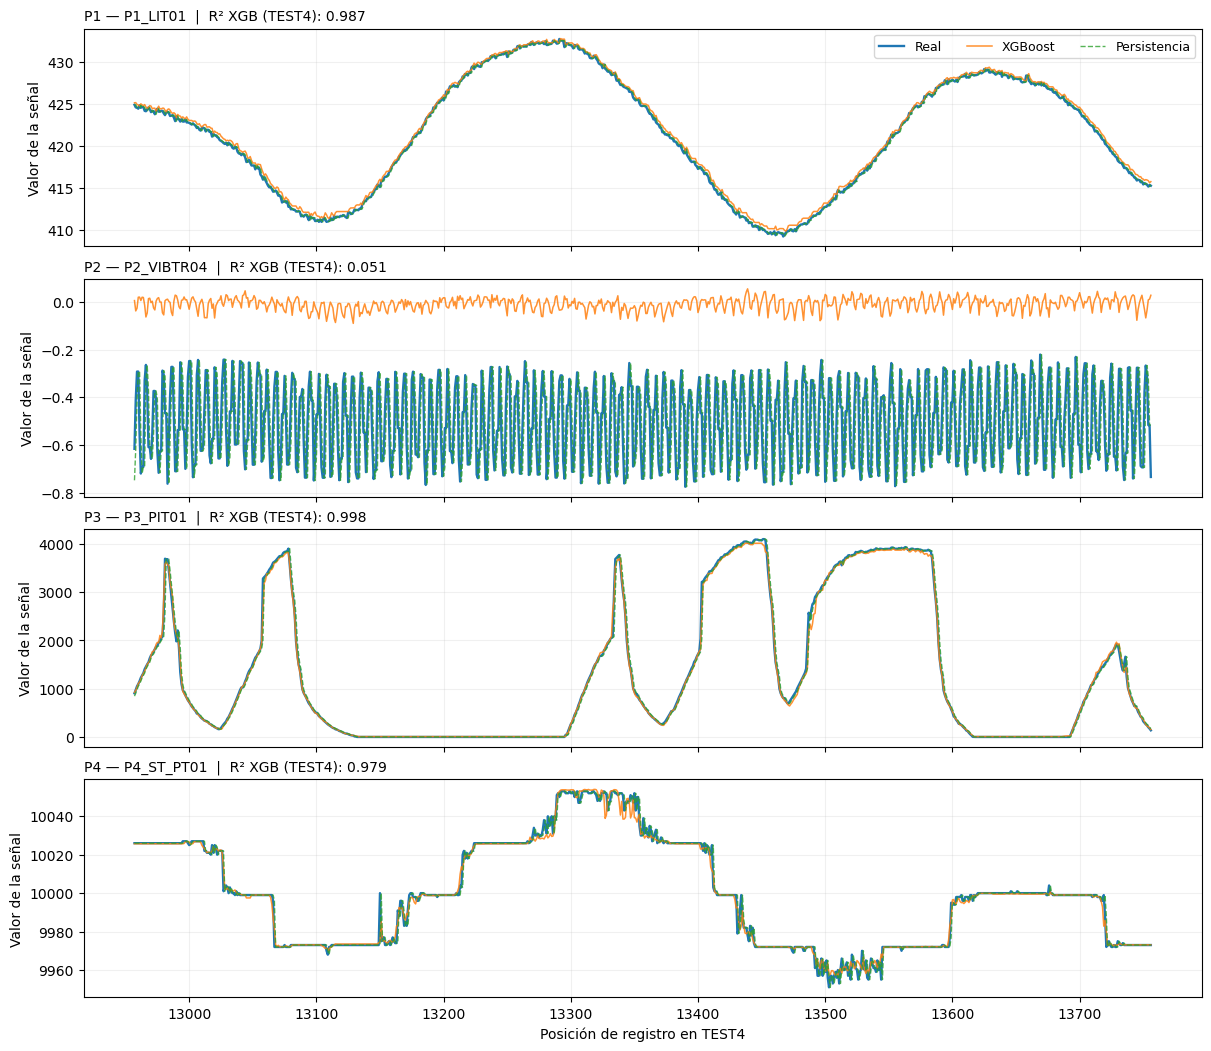

Figura y datos guardados en: C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles\analisis\etapa_1\figura_real_vs_estimado


In [4]:
fig,axes=plt.subplots(4,1,figsize=(12,10.4),sharex=True,layout='constrained')
plot_data=pd.DataFrame({'indice':xgb_window['indice'], 'timestamp':xgb_window['timestamp']})
x=np.arange(start,start+WINDOW)
for ax,item in zip(axes,selected):
    comp,var=item['componente'],item['variable']
    actual=pd.to_numeric(xgb_window[f'real__{var}'],errors='coerce').to_numpy(dtype=float)
    xgb_pred=pd.to_numeric(xgb_window[f'pred__{var}'],errors='coerce').to_numpy(dtype=float)
    persist_pred=pd.to_numeric(per_window[f'pred__{var}'],errors='coerce').to_numpy(dtype=float)
    plot_data[f'real__{var}']=actual
    plot_data[f'xgb__{var}']=xgb_pred
    plot_data[f'persist__{var}']=persist_pred
    ax.plot(x,actual,label='Real',lw=1.7)
    ax.plot(x,xgb_pred,label='XGBoost',lw=1.1,alpha=.85)
    ax.plot(x,persist_pred,label='Persistencia',lw=1,alpha=.8,ls='--')
    ax.set_title(f'({chr(97+len(ax.lines)*0)}) {comp} — {var}' if False else f'{comp} — {var}  |  R² XGB (TEST4): {item["r2_xgb"]:.3f}',loc='left',fontsize=10)
    ax.set_ylabel('Valor de la señal')
    ax.grid(alpha=.18)
axes[0].legend(loc='upper right',ncol=3,fontsize=9)
axes[-1].set_xlabel('Posición de registro en TEST4')
for ext in ('png','pdf'):
    fig.savefig(OUT/f'figura_real_vs_estimado_P1_P4_TEST4.{ext}',dpi=300,bbox_inches='tight')
plt.show()
plt.close(fig)
plot_data.to_csv(OUT/'datos_figura_real_vs_estimado.csv',index=False,encoding='utf-8-sig')
print('Figura y datos guardados en:',OUT)

## 4. Comprobación y texto para el artículo

In [5]:
expected=['seleccion_senales.csv','datos_figura_real_vs_estimado.csv',
          'figura_real_vs_estimado_P1_P4_TEST4.png','figura_real_vs_estimado_P1_P4_TEST4.pdf']
for f in expected:
    p=OUT/f
    assert p.exists() and p.stat().st_size>0, f'Falta o está vacío: {p}'
    print(f'{f}: {p.stat().st_size:,} bytes')
assert len(selection)==4 and set(selection.componente)=={'P1','P2','P3','P4'}
assert len(plot_data)==WINDOW
print('VERIFICACIÓN COMPLETADA: cuatro componentes, ventana fija y archivos producidos.')

seleccion_senales.csv: 403 bytes
datos_figura_real_vs_estimado.csv: 104,192 bytes
figura_real_vs_estimado_P1_P4_TEST4.png: 1,476,221 bytes
figura_real_vs_estimado_P1_P4_TEST4.pdf: 72,857 bytes
VERIFICACIÓN COMPLETADA: cuatro componentes, ventana fija y archivos producidos.


### Inserción en LaTeX

Copia el PDF resultante junto al archivo `.tex` de la Sección 5 y usa:

```latex
\begin{figure}[htbp]
\centering
\includegraphics[width=\linewidth]{figura_real_vs_estimado_P1_P4_TEST4.pdf}
\caption{Valores observados y estimados de una señal por componente en una
ventana fija de 800 registros de TEST4. Las señales se seleccionaron por
proximidad de su $R^2$ de XGBoost a la mediana del componente.}
\label{fig:real_vs_estimado}
\end{figure}
```

**Interpretación sugerida (breve):** La Figura~`\ref{fig:real_vs_estimado}` ilustra el seguimiento temporal de señales individuales por XGBoost y persistencia. Es una visualización local, no evidencia suficiente para identificar regímenes operacionales ni sustituye las métricas obtenidas en la totalidad de TEST4.